In [16]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [17]:
class AgentState(TypedDict):
    number1: int
    operator: str
    number2: int
    finalNumber: int

In [18]:
def adder(state: AgentState) -> AgentState:
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

def subtractor(state: AgentState) -> AgentState:
    state["finalNumber"] = state["number1"] - state["number2"]
    return state

def multiplier(state: AgentState) -> AgentState:
    state["finalNumber"] = state["number1"] * state["number2"]
    return state

def divider(state: AgentState) -> AgentState:
    state["finalNumber"] = state["number1"] / state["number2"]
    return state

def decideNextNode(state: AgentState) -> str:
    if state["operator"] == "add":
        return "adder"
    elif state["operator"] == "subtract":
        return "subtractor"
    elif state["operator"] == "multiply":
        return "multiplier"
    elif state["operator"] == "divide":
        return "divider"
    else:
        raise ValueError("Unknown operation")

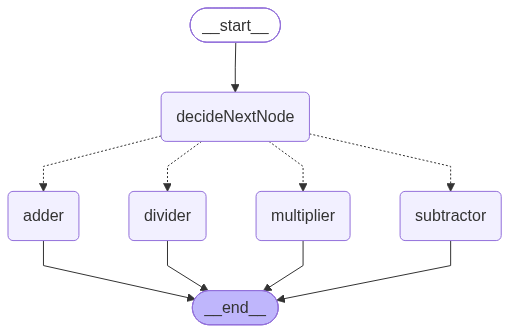

In [19]:
state = StateGraph(AgentState)
state.add_node("adder", adder)
state.add_node("subtractor", subtractor)
state.add_node("multiplier", multiplier)
state.add_node("divider", divider)
state.add_node("decideNextNode", lambda state:state)

state.add_edge(START, "decideNextNode")
state.add_conditional_edges("decideNextNode",decideNextNode, {
    "adder": "adder",
    "subtractor": "subtractor",
    "multiplier": "multiplier",
    "divider": "divider"
})

state.add_edge("adder", END)
state.add_edge("subtractor", END)
state.add_edge("multiplier", END)
state.add_edge("divider", END)

app = state.compile()
from IPython.display import display
display(app)

In [21]:
res = AgentState(number1=5,operator="multiply",number2=3)
print(app.invoke(res))


{'number1': 5, 'operator': 'multiply', 'number2': 3, 'finalNumber': 15}
